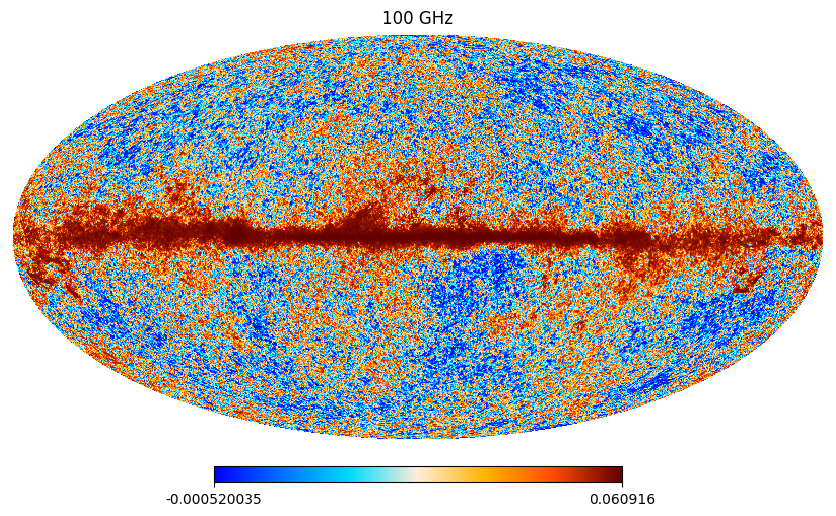

In [1]:
from matplotlib.colors import ListedColormap
import numpy as np, healpy as hp, matplotlib.cm as cm
from PIL import Image

fits_path = '../raw/HFI_SkyMap_100-field-IQU_2048_R3.00_full.fits'
cmap = ListedColormap(np.loadtxt("../raw/Planck_Parchment_RGB.txt")/255.)
m = hp.read_map(fits_path, field=0)
hp.mollview(m, norm="hist", title="100 GHz", cmap=cmap)

In [1]:
import os, numpy as np, healpy as hp
from matplotlib.colors import ListedColormap
from astropy.coordinates import SkyCoord
import astropy.units as u
from PIL import Image

FITS_PATH = '../raw/HFI_SkyMap_100-field-IQU_2048_R3.00_full.fits'
CMAP_PATH = '../raw/Planck_Parchment_RGB.txt'
OUT_DIR   = '../aux/cmb/'
N         = 1024+512   # pixels per face edge 
# (mipmaping prefers close to power-of-2)

m = hp.read_map(FITS_PATH, field=0)
m = hp.ud_grade(m, nside_out=512)
m[m == hp.UNSEEN] = np.nan
valid = ~np.isnan(m)
flat  = np.sort(m[valid])
cmap  = ListedColormap(np.loadtxt(CMAP_PATH) / 255.)

def face_directions(f, N):
    """(N*N, 3) unit vectors for OpenGL cube face f (0=px,1=nx,2=py,3=ny,4=pz,5=nz).
    Row 0 = image top, matching PIL/JPEG convention with flipY=false on CubeTextureLoader."""
    cols, rows = np.meshgrid(np.arange(N), np.arange(N))
    s = 2*(cols + 0.5)/N - 1   # [-1, 1], increases left→right
    t = 2*(rows + 0.5)/N - 1   # [-1, 1], increases top→bottom
    if   f == 0: dirs = np.stack([ np.ones_like(s),  -t,  -s], axis=-1)  # +X
    elif f == 1: dirs = np.stack([-np.ones_like(s),  -t,   s], axis=-1)  # -X
    elif f == 2: dirs = np.stack([ s,  np.ones_like(s),   t], axis=-1)   # +Y
    elif f == 3: dirs = np.stack([ s, -np.ones_like(s),  -t], axis=-1)   # -Y
    elif f == 4: dirs = np.stack([ s,  -t,  np.ones_like(s)], axis=-1)   # +Z
    elif f == 5: dirs = np.stack([-s,  -t, -np.ones_like(s)], axis=-1)   # -Z
    norms = np.linalg.norm(dirs, axis=-1, keepdims=True)
    return (dirs / norms).reshape(-1, 3)

for f, name in enumerate(['px', 'nx', 'py', 'ny', 'pz', 'nz']):
    dirs = face_directions(f, N)
    x, y, z = dirs[:,0], dirs[:,1], dirs[:,2]

    # ICRS direction → RA/Dec
    ra_rad  = np.arctan2(y, x) % (2*np.pi)
    dec_rad = np.arcsin(np.clip(z, -1.0, 1.0))

    # ICRS → Galactic (for HEALPix map frame)
    eq  = SkyCoord(ra=ra_rad*u.rad, dec=dec_rad*u.rad, frame='icrs')
    gal = eq.galactic
    theta = np.pi/2 - gal.b.rad     # colatitude: 0 = north galactic pole
    phi   = gal.l.rad % (2*np.pi)   # galactic longitude

    # Sample HEALPix map
    vals = hp.get_interp_val(np.where(valid, m, 0.0), theta, phi)

    # Histogram normalise → Parchment colormap → JPEG
    norm_vals = (np.searchsorted(flat, vals) / len(flat)).reshape(N, N)
    rgb = (cmap(norm_vals)[:,:,:3] * 255).astype(np.uint8)
    out = os.path.join(OUT_DIR, f'planck_100ghz_{name}.jpg')
    Image.fromarray(rgb).save(out, quality=85)
    print(f'Saved {out}  ({os.path.getsize(out)//1024} KB)')


Saved ../aux/cmb/planck_100ghz_px.jpg  (996 KB)
Saved ../aux/cmb/planck_100ghz_nx.jpg  (1004 KB)
Saved ../aux/cmb/planck_100ghz_py.jpg  (919 KB)
Saved ../aux/cmb/planck_100ghz_ny.jpg  (911 KB)
Saved ../aux/cmb/planck_100ghz_pz.jpg  (890 KB)
Saved ../aux/cmb/planck_100ghz_nz.jpg  (892 KB)


In [2]:
import os, numpy as np, healpy as hp
from matplotlib.colors import ListedColormap
from astropy.coordinates import SkyCoord
import astropy.units as u
from PIL import Image

FITS_PATH = '../raw/HFI_SkyMap_100-field-IQU_2048_R3.00_full.fits'
CMAP_PATH = '../raw/Planck_Parchment_RGB.txt'
OUT_DIR   = '../aux/cmb/'
W, H      = 4096+2048, 2048+1024
# (mipmaping prefers close to power-of-2)
OUT_FILE  = os.path.join(OUT_DIR, 'planck_100ghz.jpg')

os.makedirs(OUT_DIR, exist_ok=True)

# Load and prepare HEALPix map (Galactic frame)
m = hp.read_map(FITS_PATH, field=0)
m = hp.ud_grade(m, nside_out=512)
m[m == hp.UNSEEN] = np.nan
valid = ~np.isnan(m)
flat  = np.sort(m[valid])
cmap  = ListedColormap(np.loadtxt(CMAP_PATH) / 255.)

# Equirectangular grid: RA=0/DEC=0 at centre; RA increases leftward
cols, rows = np.meshgrid(np.arange(W), np.arange(H))
ra_deg  = (0.5 - (cols + 0.5) / W) * 360   # col 0 → +180°, col W/2 → 0°, col W-1 → −180°
dec_deg = (0.5 - (rows + 0.5) / H) * 180   # row 0 → +90°,  row H/2 → 0°, row H-1 → −90°
del cols, rows

ra_flat  = (ra_deg % 360).ravel()   # wrap into [0°, 360°) for SkyCoord
dec_flat = dec_deg.ravel()
del ra_deg, dec_deg

# ICRS → Galactic (HEALPix map is in Galactic frame)
eq  = SkyCoord(ra=ra_flat * u.deg, dec=dec_flat * u.deg, frame='icrs')
gal = eq.galactic
theta = np.pi/2 - gal.b.rad        # healpy colatitude [0, π]
phi   = gal.l.rad % (2 * np.pi)    # healpy longitude  [0, 2π)
del ra_flat, dec_flat, eq, gal

# Sample HEALPix map via bilinear interpolation
vals = hp.get_interp_val(np.where(valid, m, 0.0), theta, phi)
del theta, phi

# Histogram normalisation → Planck Parchment colormap → JPEG
norm_vals = (np.searchsorted(flat, vals) / len(flat)).reshape(H, W)
del vals
rgb = (cmap(norm_vals)[:, :, :3] * 255).astype(np.uint8)
Image.fromarray(rgb).save(OUT_FILE, quality=85)
print(f'Saved {OUT_FILE}  ({os.path.getsize(OUT_FILE)//1024} KB)')


Saved ../aux/cmb/planck_100ghz.jpg  (6668 KB)
